In [1]:
# AtmoSync - Micro-Climate Analytics
# Bengaluru vs Chennai | October 2026

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


print("AtmoSync - Micro-Climate Analytics")
print("Python environment is ready let's begin")

AtmoSync - Micro-Climate Analytics
Python environment is ready let's begin


In [2]:
# Load the AtmoSync dataset

file_path = "../data/raw/atmosync_bengaluru_chennai_oct2026.csv"

df = pd.read_csv(file_path)

# Display basic information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Display first 5 rows
df.head()

Dataset loaded successfully!
Dataset shape: (1488, 9)


,timestamp,city,latitude,longitude,elevation_m,temperature_c,relative_humidity_pct,wind_speed_kmh,precipitation_mm
0,2026-10-01 00:00:00,Bengaluru,12.970123,77.56364,910.0,21.4,94,1.0,0.1
1,2026-10-01 00:00:00,Chennai,13.110721,80.24590,12.0,28.3,87,4.7,0.0
2,2026-10-01 01:00:00,Bengaluru,12.970123,77.56364,910.0,21.4,94,1.5,0.0
3,2026-10-01 01:00:00,Chennai,13.110721,80.24590,12.0,27.5,87,5.4,0.0
4,2026-10-01 02:00:00,Bengaluru,12.970123,77.56364,910.0,21.0,95,1.5,0.0


In [3]:
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

Total rows: 1488
Total columns: 9


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1488 entries, 0 to 1487
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   timestamp              1488 non-null   object 
 1   city                   1488 non-null   object 
 2   latitude               1488 non-null   float64
 3   longitude              1488 non-null   float64
 4   elevation_m            1488 non-null   float64
 5   temperature_c          1488 non-null   float64
 6   relative_humidity_pct  1488 non-null   int64  
 7   wind_speed_kmh         1488 non-null   float64
 8   precipitation_mm       1488 non-null   float64
dtypes: float64(6), int64(1), object(2)
memory usage: 104.8+ KB


In [5]:
#Here we are converting the object datatype into datetime:
df["timestamp"]=pd.to_datetime(df["timestamp"])
print(df["timestamp"].dtype)

datetime64[ns]


In [6]:
#Know lets check the missing values in our Dataset:
nu = df.isnull()

In [7]:
nu.sum()

timestamp                0
city                     0
latitude                 0
longitude                0
elevation_m              0
temperature_c            0
relative_humidity_pct    0
wind_speed_kmh           0
precipitation_mm         0
dtype: int64

In [8]:
# We have to check whether there are Duplicated Rows:
dup =df.duplicated() 
dup

0       False
1       False
2       False
3       False
4       False
        ...  
1483    False
1484    False
1485    False
1486    False
1487    False
Length: 1488, dtype: bool

In [9]:
dup.sum()

0

In [10]:
# Checking the number of records for each city

city_counts = df["city"].value_counts()

print("Number of records for each city:")
print(city_counts)

Number of records for each city:
city
Bengaluru    744
Chennai      744
Name: count, dtype: int64


## Data Quality and City Record Distribution

### Data Quality Findings
- Total records: 1,488
- Missing values: 0
- Duplicate rows: 0

### City-wise Record Distribution
The dataset contains hourly weather observations for Bengaluru and Chennai during October 2026.

The city-wise record counts were checked to understand the distribution of observations across both cities.

In [11]:
# Calculating city-wise record percentage

city_percentage = (city_counts / len(df)) * 100

print("City-wise record percentage:")
print(city_percentage.round(2))

City-wise record percentage:
city
Bengaluru    50.0
Chennai      50.0
Name: count, dtype: float64


### City-wise Record Percentage

The percentage distribution of records was calculated for Bengaluru and Chennai.

This analysis helps identify the contribution of each city to the overall dataset and understand whether the observations are evenly distributed or concentrated in one city.

## Numerical Data Analysis

In [12]:
# Statistical summary of numerical columns

df.describe()

,timestamp,latitude,longitude,elevation_m,temperature_c,relative_humidity_pct,wind_speed_kmh,precipitation_mm
count,1488,1488.000000,1488.000000,1488.00000,1488.000000,1488.000000,1488.000000,1488.00000
mean,2026-10-16 11:29:59.999999744,13.040422,78.904770,461.00000,26.410753,73.361559,8.478763,0.24086
min,2026-10-01 00:00:00,12.970123,77.563640,12.00000,17.400000,30.000000,0.400000,0.00000
25%,2026-10-08 17:45:00,12.970123,77.563640,12.00000,23.300000,60.000000,6.100000,0.00000
50%,2026-10-16 11:30:00,13.040422,78.904770,461.00000,26.800000,75.000000,8.300000,0.00000
75%,2026-10-24 05:15:00,13.110721,80.245900,910.00000,29.200000,88.000000,10.700000,0.10000
max,2026-10-31 23:00:00,13.110721,80.245900,910.00000,35.300000,99.000000,20.700000,16.00000
std,NaN,0.070323,1.341581,449.15095,3.761008,17.071381,3.609094,0.91089


### Statistical Summary – Key Observations

- The dataset contains 1,488 observations.
- Average temperature is approximately 26.41°C.
- Temperature ranges from 17.4°C to 35.3°C.
- Average relative humidity is approximately 73.36%.
- Relative humidity ranges from 30% to 99%.
- Average wind speed is approximately 8.48 km/h.
- Wind speed ranges from 0.4 km/h to 20.7 km/h.
- Average precipitation is approximately 0.24 mm.
- The dataset covers observations from October 1 to October 31, 2026.

The statistical summary provides an overview of the distribution, central tendency and variability of the numerical variables.

## Individual Numerical Column Analysis

### Temperature Distribution

In [13]:
# Temperature distribution statistics

print("Temperature Analysis")
print("Mean:", df["temperature_c"].mean())
print("Median:", df["temperature_c"].median())
print("Minimum:", df["temperature_c"].min())
print("Maximum:", df["temperature_c"].max())
print("Standard Deviation:", df["temperature_c"].std())

Temperature Analysis
Mean: 26.410752688172042
Median: 26.8
Minimum: 17.4
Maximum: 35.3
Standard Deviation: 3.761008317220068


### Temperature Analysis – Key Observations

- The average temperature is approximately 26.41°C.
- The median temperature is 26.8°C.
- The minimum recorded temperature is 17.4°C.
- The maximum recorded temperature is 35.3°C.
- The standard deviation is approximately 3.76°C, indicating the spread of temperature values around the mean.

These results provide an understanding of temperature distribution and variation across the dataset.

In [14]:
# Relative Humidity Analysis

print("Relative Humidity Analysis")
print("Mean:", df["relative_humidity_pct"].mean())
print("Median:", df["relative_humidity_pct"].median())
print("Minimum:", df["relative_humidity_pct"].min())
print("Maximum:", df["relative_humidity_pct"].max())
print("Standard Deviation:", df["relative_humidity_pct"].std())

Relative Humidity Analysis
Mean: 73.36155913978494
Median: 75.0
Minimum: 30
Maximum: 99
Standard Deviation: 17.07138147177724


In [15]:
# Wind Speed Analysis

print("Wind Speed Analysis")
print("Mean:", df["wind_speed_kmh"].mean())
print("Median:", df["wind_speed_kmh"].median())
print("Minimum:", df["wind_speed_kmh"].min())
print("Maximum:", df["wind_speed_kmh"].max())
print("Standard Deviation:", df["wind_speed_kmh"].std())

Wind Speed Analysis
Mean: 8.478763440860215
Median: 8.3
Minimum: 0.4
Maximum: 20.7
Standard Deviation: 3.6090941813944957


In [16]:
# Temperature vs Relative Humidity

correlation = df["temperature_c"].corr(df["relative_humidity_pct"])

print("Correlation between Temperature and Relative Humidity:", correlation)

Correlation between Temperature and Relative Humidity: -0.6154748496869411


### Observation

The correlation between temperature and relative humidity is -0.6155,
indicating a moderate negative relationship. This suggests that higher
temperatures are generally associated with lower relative humidity
in the collected dataset.

In [17]:
# Temperature vs Wind Speed

correlation = df["temperature_c"].corr(df["wind_speed_kmh"])

print("Correlation between Temperature and Wind Speed:", correlation)

Correlation between Temperature and Wind Speed: 0.21355716653613158


# Relative Humidity vs Wind Speed

correlation = df["relative_humidity_pct"].corr(df["wind_speed_kmh"])

print("Correlation between Relative Humidity and Wind Speed:", correlation)

In [18]:
# Relative Humidity vs Wind Speed

correlation = df["relative_humidity_pct"].corr(df["wind_speed_kmh"])

print("Correlation between Relative Humidity and Wind Speed:", correlation)

Correlation between Relative Humidity and Wind Speed: -0.3016608400806466


### Observation

The correlation between relative humidity and wind speed is -0.3017,
indicating a weak negative relationship. This suggests that wind
speed tends to decrease slightly as relative humidity increases.

In [19]:
# Correlation Matrix

correlation_matrix = df[
    ["temperature_c", "relative_humidity_pct", "wind_speed_kmh"]
].corr()

print("Correlation Matrix:")
print(correlation_matrix)

Correlation Matrix:
                       temperature_c  relative_humidity_pct  wind_speed_kmh
temperature_c               1.000000              -0.615475        0.213557
relative_humidity_pct      -0.615475               1.000000       -0.301661
wind_speed_kmh              0.213557              -0.301661        1.000000


### Correlation Matrix - Key Findings

- Temperature and relative humidity show a moderate negative correlation (-0.6155).
- Temperature and wind speed show a weak positive correlation (+0.2136).
- Relative humidity and wind speed show a weak negative correlation (-0.3017).

Overall, temperature and relative humidity have the strongest relationship
among the three variable pairs in this dataset.

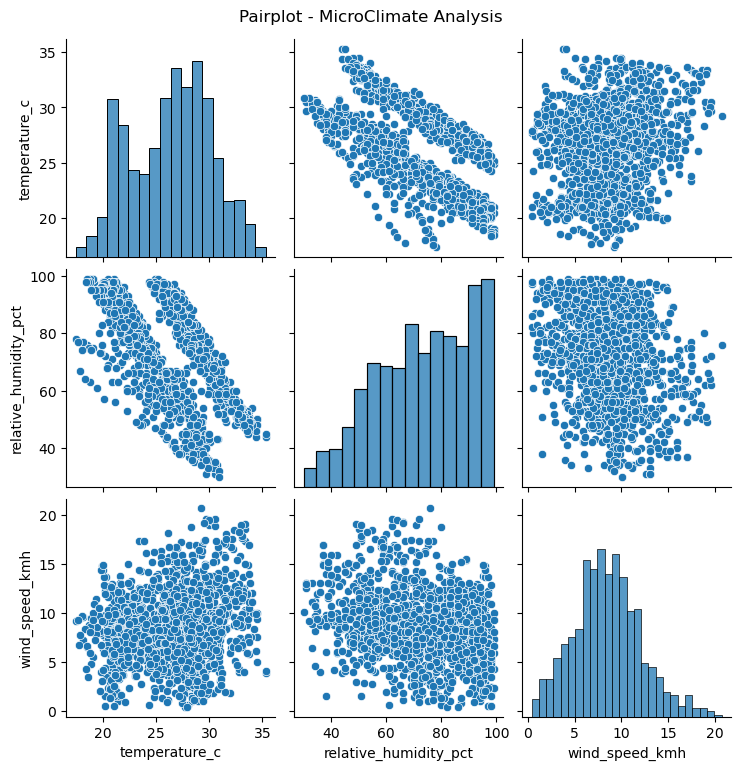

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(
    df[['temperature_c', 'relative_humidity_pct', 'wind_speed_kmh']],
    diag_kind='hist'
)

plt.suptitle('Pairplot - MicroClimate Analysis', y=1.02)
plt.show()

In [21]:
print(df.columns.tolist())

['timestamp', 'city', 'latitude', 'longitude', 'elevation_m', 'temperature_c', 'relative_humidity_pct', 'wind_speed_kmh', 'precipitation_mm']


### Pairplot Analysis – Key Findings

Pairplot analysis was performed to examine the relationships and distributions of temperature, relative humidity, and wind speed.

**Key observations:**

1. Temperature and relative humidity exhibit a moderate negative relationship, indicating that higher temperatures are generally associated with lower relative humidity.
2. Temperature and wind speed show a weak positive association.
3. Relative humidity and wind speed demonstrate a weak negative association.
4. The temperature distribution displays multiple peaks, suggesting variations across observations.
5. Wind speed follows a right-skewed distribution, with most observations concentrated at relatively lower wind speeds.
6. Relative humidity observations are more concentrated toward higher values.

**Conclusion:**

The pairplot analysis confirms that temperature and relative humidity have the strongest relationship among the three variable pairs. These findings provide useful insights into the relationships between different microclimatic variables.

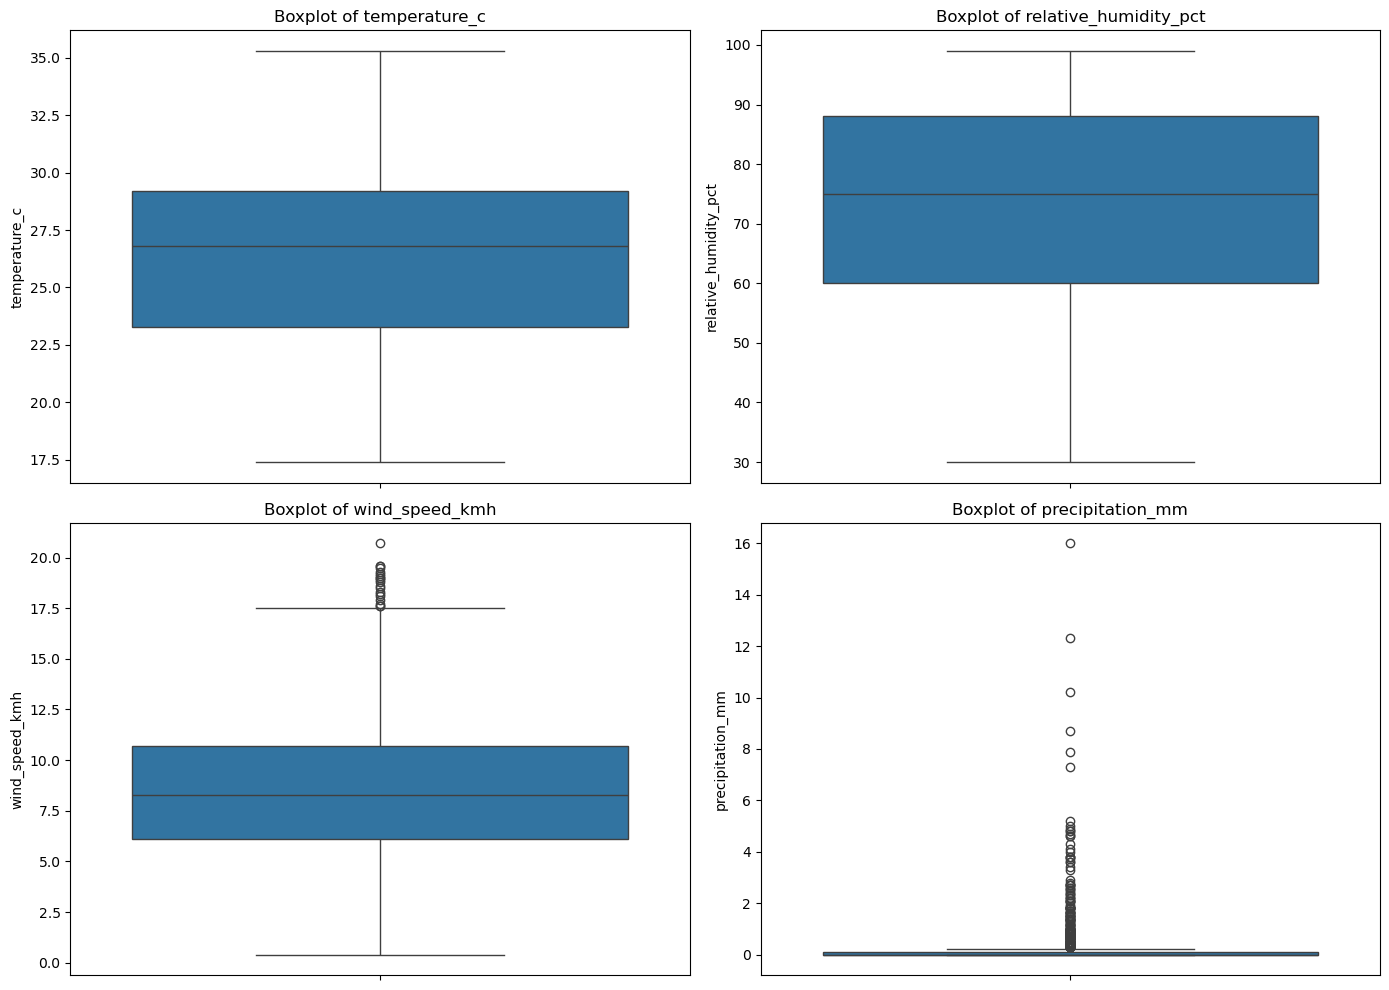

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_cols = [
    'temperature_c',
    'relative_humidity_pct',
    'wind_speed_kmh',
    'precipitation_mm'
]

plt.figure(figsize=(14, 10))

for i, col in enumerate(numerical_cols, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

In [23]:
numerical_cols = [
    'temperature_c',
    'relative_humidity_pct',
    'wind_speed_kmh',
    'precipitation_mm'
]

for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"\nColumn: {col}")
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Outlier Count:", len(outliers))
    print("Outlier Percentage:",
          round(len(outliers) / len(df) * 100, 2), "%")


Column: temperature_c
Lower Bound: 14.450000000000003
Upper Bound: 38.05
Outlier Count: 0
Outlier Percentage: 0.0 %

Column: relative_humidity_pct
Lower Bound: 18.0
Upper Bound: 130.0
Outlier Count: 0
Outlier Percentage: 0.0 %

Column: wind_speed_kmh
Lower Bound: -0.7999999999999998
Upper Bound: 17.599999999999998
Outlier Count: 20
Outlier Percentage: 1.34 %

Column: precipitation_mm
Lower Bound: -0.15000000000000002
Upper Bound: 0.25
Outlier Count: 234
Outlier Percentage: 15.73 %


### IQR-Based Outlier Detection – Key Findings

The Interquartile Range (IQR) method was applied to identify potential outliers in the numerical variables of the AtomSync MicroClimate Analytics dataset.

**Results:**

1. Temperature: No outliers were detected (0%).
2. Relative Humidity: No outliers were detected (0%).
3. Wind Speed: 20 outliers were identified (1.34%).
4. Precipitation: 234 outliers were identified (15.73%).

**Conclusion:**

Precipitation contains the highest proportion of potential outliers, followed by wind speed. Temperature and relative humidity show no outliers based on the IQR method.

These observations require further investigation before applying any outlier treatment. Extreme precipitation and wind-speed values may represent genuine weather events rather than data errors.

In [24]:
Q1 = df['precipitation_mm'].quantile(0.25)
Q3 = df['precipitation_mm'].quantile(0.75)

IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

precipitation_outliers = df[
    df['precipitation_mm'] > upper_bound
]

print(precipitation_outliers[
    ['timestamp', 'city', 'temperature_c',
     'relative_humidity_pct', 'wind_speed_kmh',
     'precipitation_mm']
].head(10))

              timestamp       city  temperature_c  relative_humidity_pct  \
28  2026-10-01 14:00:00  Bengaluru           28.4                     54   
105 2026-10-03 04:00:00    Chennai           26.8                     80   
107 2026-10-03 05:00:00    Chennai           28.2                     78   
111 2026-10-03 07:00:00    Chennai           28.0                     79   
188 2026-10-04 22:00:00  Bengaluru           24.1                     73   
220 2026-10-05 14:00:00  Bengaluru           27.0                     56   
221 2026-10-05 14:00:00    Chennai           31.9                     60   
222 2026-10-05 15:00:00  Bengaluru           26.4                     62   
223 2026-10-05 15:00:00    Chennai           32.2                     60   
226 2026-10-05 17:00:00  Bengaluru           24.9                     75   

     wind_speed_kmh  precipitation_mm  
28              9.2               0.3  
105             5.3               0.6  
107             4.7               0.3  
111

In [25]:
#Participation During Anlaysis:
print("Precipitation Summary:")
print(df['precipitation_mm'].describe())

print("\nZero Precipitation Count:")
print((df['precipitation_mm'] == 0).sum())

print("\nNon-Zero Precipitation Count:")
print((df['precipitation_mm'] > 0).sum())

print("\nUnique Precipitation Values:")
print(df['precipitation_mm'].nunique())

Precipitation Summary:
count    1488.00000
mean        0.24086
std         0.91089
min         0.00000
25%         0.00000
50%         0.00000
75%         0.10000
max        16.00000
Name: precipitation_mm, dtype: float64

Zero Precipitation Count:
1067

Non-Zero Precipitation Count:
421

Unique Precipitation Values:
50


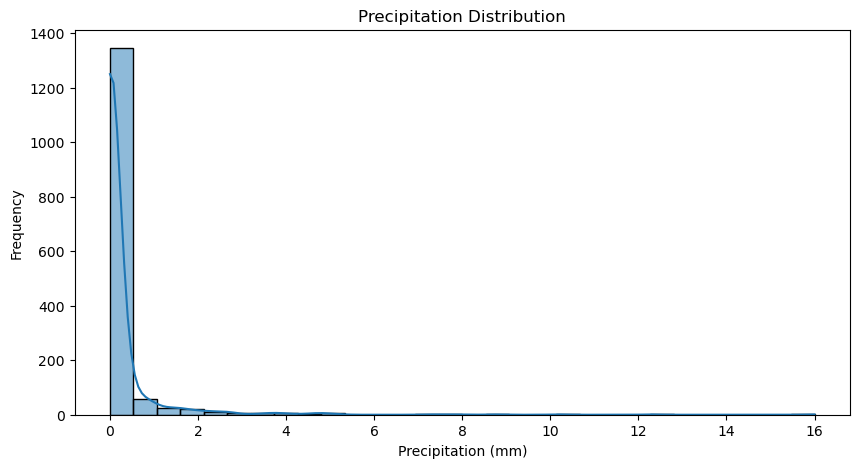

In [26]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='precipitation_mm',
    bins=30,
    kde=True
)

plt.title('Precipitation Distribution')
plt.xlabel('Precipitation (mm)')
plt.ylabel('Frequency')

plt.show()

In [27]:
#Convert timestamp into datetime:
df['timestamp'] = pd.to_datetime(df['timestamp'])

print(df['timestamp'].dtype)

datetime64[ns]


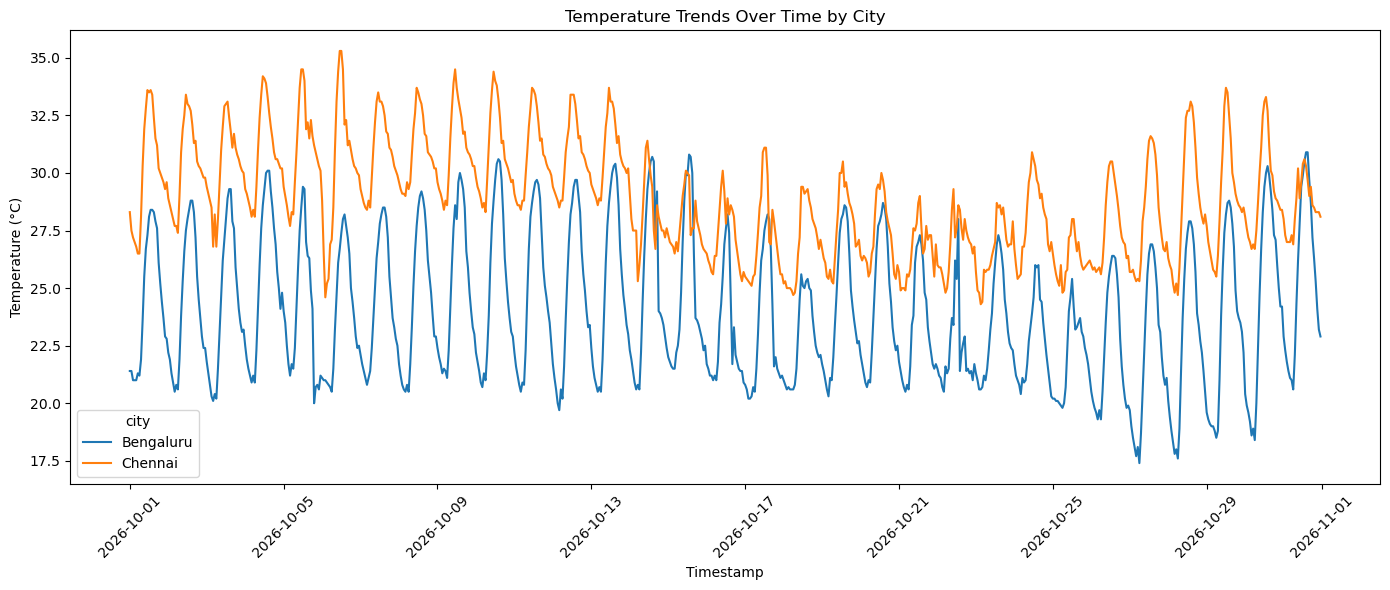

In [28]:
#Analyse temperature trends by city:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=df,
    x='timestamp',
    y='temperature_c',
    hue='city'
)

plt.title('Temperature Trends Over Time by City')
plt.xlabel('Timestamp')
plt.ylabel('Temperature (°C)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

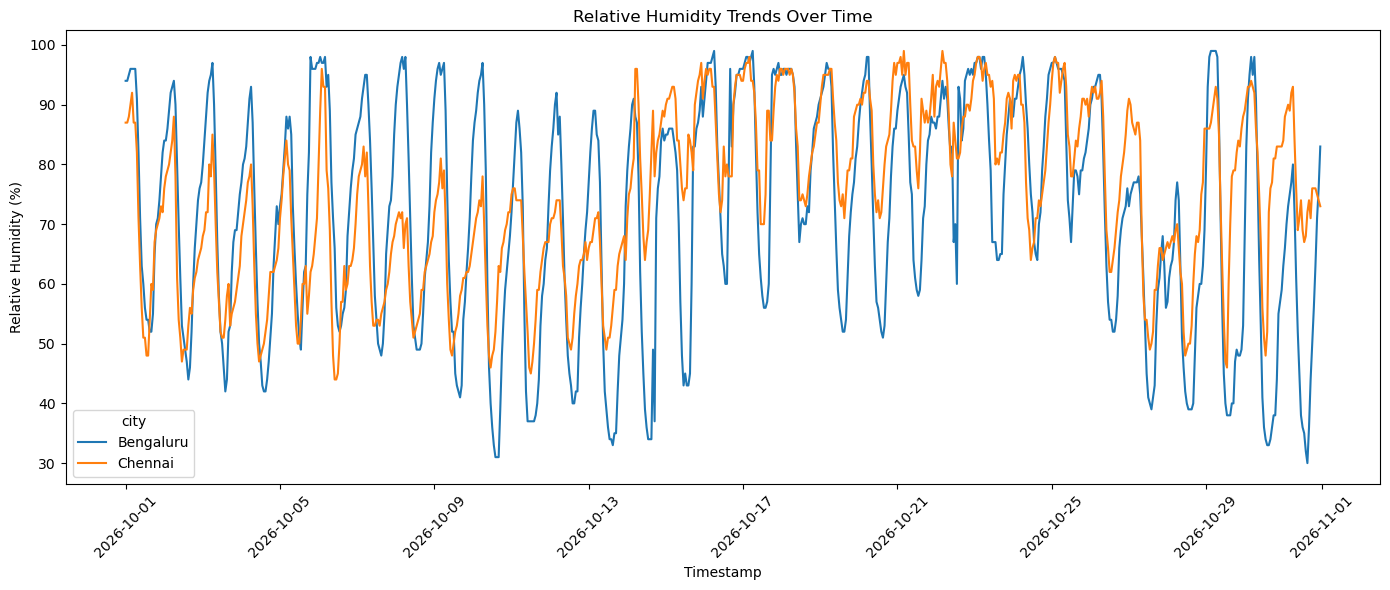

In [29]:
#Analyse humidity trends by city:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=df,
    x='timestamp',
    y='relative_humidity_pct',
    hue='city'
)

plt.title('Relative Humidity Trends Over Time')
plt.xlabel('Timestamp')
plt.ylabel('Relative Humidity (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

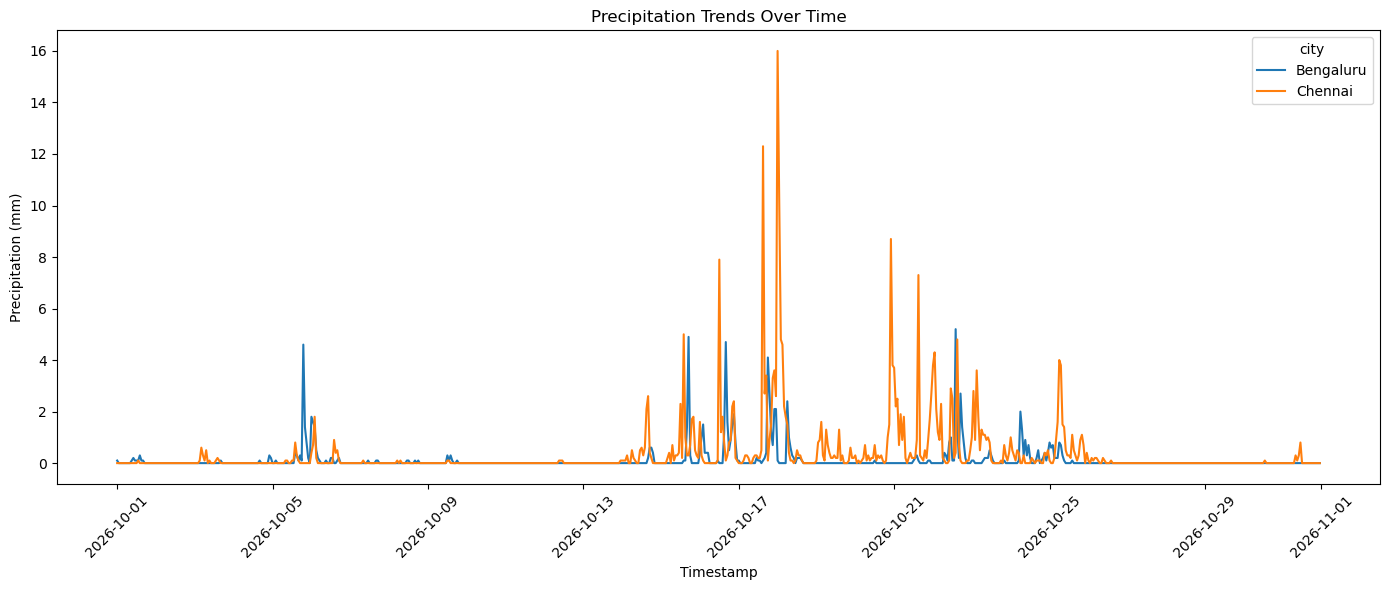

In [30]:
#Analyse precipitation trends by city:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=df,
    x='timestamp',
    y='precipitation_mm',
    hue='city'
)

plt.title('Precipitation Trends Over Time')
plt.xlabel('Timestamp')
plt.ylabel('Precipitation (mm)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [31]:
# Precipitation Summary Analysis

precip = df['precipitation_mm'].dropna()

print("Precipitation Analysis")
print("----------------------")
print("Total Records:", len(precip))
print("Average Precipitation:", precip.mean())
print("Median Precipitation:", precip.median())
print("Maximum Precipitation:", precip.max())
print("Minimum Precipitation:", precip.min())
print("Total Precipitation:", precip.sum())

print("\nRainfall Distribution")
print("----------------------")
print("Records with Rainfall:", (precip > 0).sum())
print("Records with No Rainfall:", (precip == 0).sum())
print("Missing Values:", df['precipitation_mm'].isnull().sum())

Precipitation Analysis
----------------------
Total Records: 1488
Average Precipitation: 0.24086021505376343
Median Precipitation: 0.0
Maximum Precipitation: 16.0
Minimum Precipitation: 0.0
Total Precipitation: 358.4

Rainfall Distribution
----------------------
Records with Rainfall: 421
Records with No Rainfall: 1067
Missing Values: 0


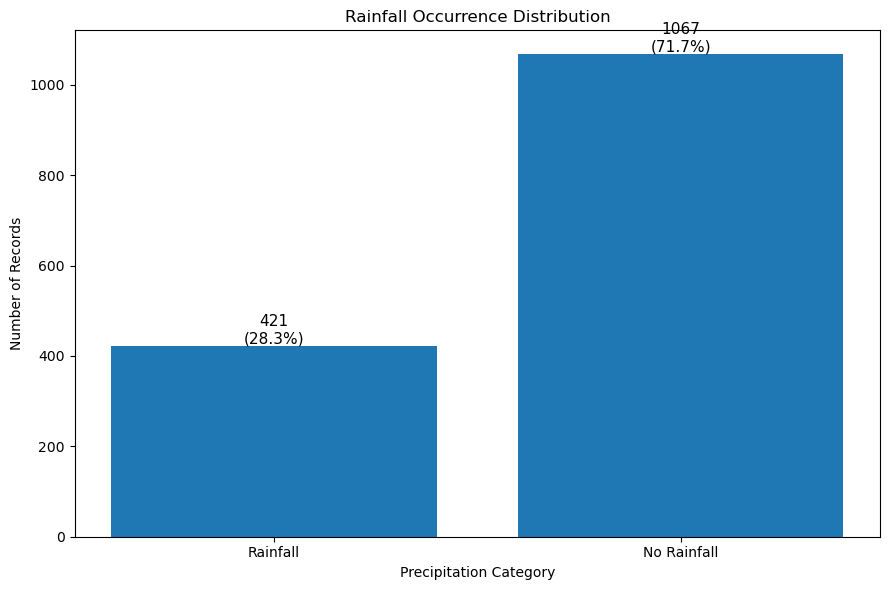

In [32]:
# Rainfall Distribution:
# Rainfall vs No Rainfall Distribution

rainfall_counts = [
    (df['precipitation_mm'] > 0).sum(),
    (df['precipitation_mm'] == 0).sum()
]

labels = ['Rainfall', 'No Rainfall']

percentages = [
    (count / len(df)) * 100
    for count in rainfall_counts
]

plt.figure(figsize=(9, 6))

bars = plt.bar(labels, rainfall_counts)

plt.title('Rainfall Occurrence Distribution')
plt.xlabel('Precipitation Category')
plt.ylabel('Number of Records')

for bar, count, percentage in zip(
    bars, rainfall_counts, percentages
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{count}\n({percentage:.1f}%)',
        ha='center',
        va='bottom',
        fontsize=11
    )

plt.tight_layout()

# Export chart in SVG format
plt.savefig(
    'rainfall_distribution.svg',
    format='svg',
    bbox_inches='tight'
)

plt.show()

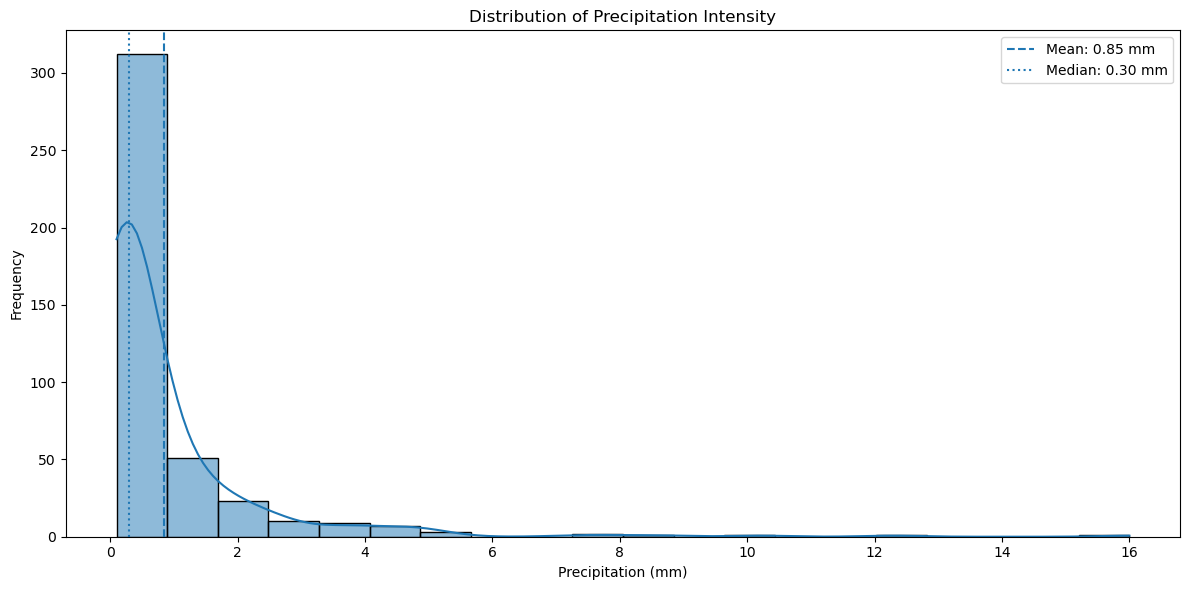

In [33]:
# Analyse Precipitation Intensity Distribution

rainy_data = df[df['precipitation_mm'] > 0]['precipitation_mm']

plt.figure(figsize=(12, 6))

sns.histplot(
    rainy_data,
    bins=20,
    kde=True
)

plt.axvline(
    rainy_data.mean(),
    linestyle='--',
    label=f'Mean: {rainy_data.mean():.2f} mm'
)

plt.axvline(
    rainy_data.median(),
    linestyle=':',
    label=f'Median: {rainy_data.median():.2f} mm'
)

plt.title('Distribution of Precipitation Intensity')
plt.xlabel('Precipitation (mm)')
plt.ylabel('Frequency')
plt.legend()

plt.tight_layout()

plt.savefig(
    'precipitation_intensity_distribution.svg',
    format='svg',
    bbox_inches='tight'
)

plt.show()

In [34]:
#Rainfall Intensity Statistics:
# Rainfall Intensity Statistical Analysis

rainy_data = df[df['precipitation_mm'] > 0]['precipitation_mm']

print("RAINPadALL INTENSITY ANALYSIS")
print("-----------------------------")
print("Rainy Observations:", len(rainy_data))
print("Average Intensity:", round(rainy_data.mean(), 2), "mm")
print("Median Intensity:", round(rainy_data.median(), 2), "mm")
print("25th Percentile:", round(rainy_data.quantile(0.25), 2), "mm")
print("75th Percentile:", round(rainy_data.quantile(0.75), 2), "mm")
print("Maximum Intensity:", rainy_data.max(), "mm")
print("Standard Deviation:", round(rainy_data.std(), 2), "mm")

RAINPadALL INTENSITY ANALYSIS
-----------------------------
Rainy Observations: 421
Average Intensity: 0.85 mm
Median Intensity: 0.3 mm
25th Percentile: 0.1 mm
75th Percentile: 0.9 mm
Maximum Intensity: 16.0 mm
Standard Deviation: 1.55 mm


PRECIPITATION OUTLIER ANALYSIS
------------------------------
Q1: 0.1
Q3: 0.9
IQR: 0.8
Lower Bound: -1.1
Upper Bound: 2.1
Total Outliers: 42

Outlier Values:
[16.0, 12.3, 10.2, 8.7, 7.9, 7.3, 5.2, 5.0, 4.9, 4.8, 4.8, 4.7, 4.6, 4.6, 4.3, 4.1, 4.0, 3.8, 3.8, 3.8, 3.7, 3.6, 3.6, 3.4, 3.3, 2.9, 2.8, 2.7, 2.7, 2.7, 2.7, 2.6, 2.6, 2.5, 2.5, 2.4, 2.4, 2.3, 2.3, 2.2, 2.2, 2.2]


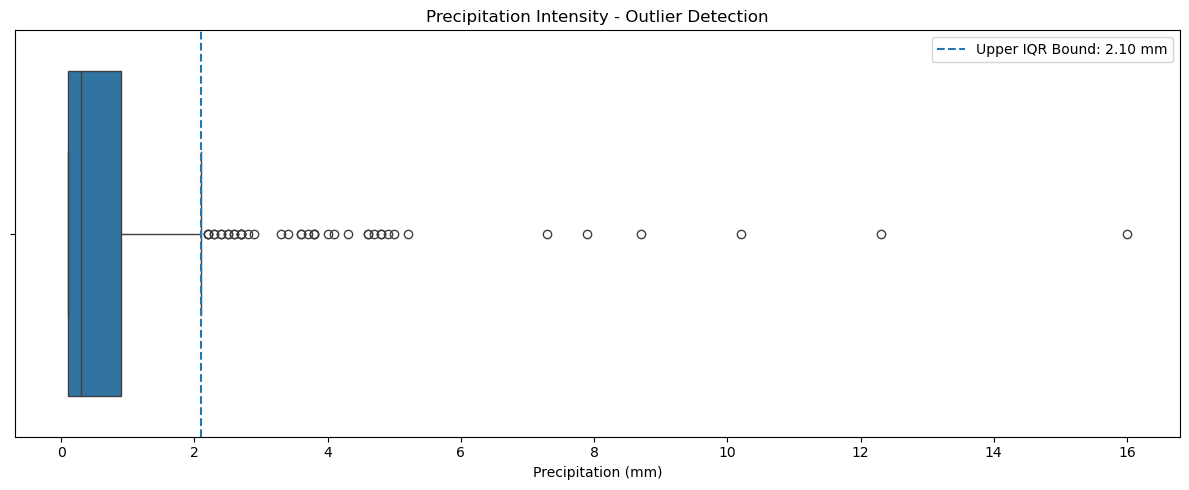

In [35]:
#IQR Outlier Detection for Precipitation:
# IQR-Based Precipitation Outlier Detection

rainy_data = df.loc[
    df['precipitation_mm'] > 0,
    'precipitation_mm'
].dropna()

Q1 = rainy_data.quantile(0.25)
Q3 = rainy_data.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

outliers = rainy_data[
    (rainy_data < lower_bound) |
    (rainy_data > upper_bound)
]

print("PRECIPITATION OUTLIER ANALYSIS")
print("------------------------------")
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Total Outliers:", len(outliers))

print("\nOutlier Values:")
print(outliers.sort_values(ascending=False).to_list())

# Visualize outliers using Boxplot
plt.figure(figsize=(12, 5))

sns.boxplot(x=rainy_data)

plt.axvline(
    upper_bound,
    linestyle='--',
    label=f'Upper IQR Bound: {upper_bound:.2f} mm'
)

plt.title('Precipitation Intensity - Outlier Detection')
plt.xlabel('Precipitation (mm)')
plt.legend()
plt.tight_layout()

plt.savefig(
    'precipitation_outlier_analysis.svg',
    format='svg',
    bbox_inches='tight'
)

plt.show()

In [36]:
# Precipitation Outlier Analysis using IQR Method

precip = df['precipitation_mm'].dropna()

# Calculate Quartiles
Q1 = precip.quantile(0.25)
Q3 = precip.quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate Lower and Upper Bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify Outliers
outliers = precip[
    (precip < lower_bound) | (precip > upper_bound)
]

# Display Results
print("PRECIPITATION OUTLIER ANALYSIS")
print("------------------------------")
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Total Outliers:", len(outliers))
print("\nOutlier Values:")
print(sorted(outliers.tolist()))

PRECIPITATION OUTLIER ANALYSIS
------------------------------
Q1: 0.0
Q3: 0.1
IQR: 0.1
Lower Bound: -0.15000000000000002
Upper Bound: 0.25
Total Outliers: 234

Outlier Values:
[0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.4, 0.4, 0.4, 0.4, 0.4, 0.4, 0.4, 0.4, 0.4, 0.4, 0.4, 0.4, 0.4, 0.4, 0.4, 0.4, 0.4, 0.4, 0.4, 0.4, 0.4, 0.4, 0.4, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.7, 0.7, 0.7, 0.7, 0.7, 0.7, 0.7, 0.7, 0.7, 0.7, 0.7, 0.7, 0.7, 0.7, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.1, 1.1, 1.1, 1.1, 1.2, 1.2, 1.2, 1.2, 1.3, 1.3, 1.3, 1.3, 1.4, 1.4, 1.4, 1.4, 1.4, 1.4

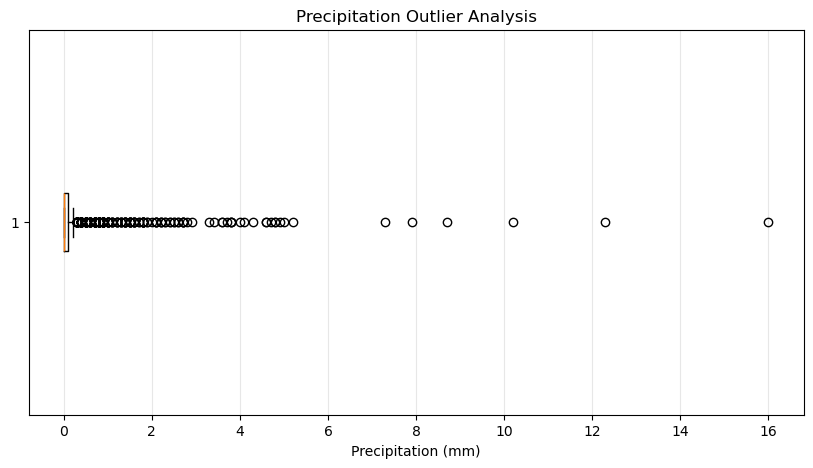

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.boxplot(precip, vert=False)

plt.title("Precipitation Outlier Analysis")
plt.xlabel("Precipitation (mm)")
plt.grid(axis='x', alpha=0.3)

plt.show()

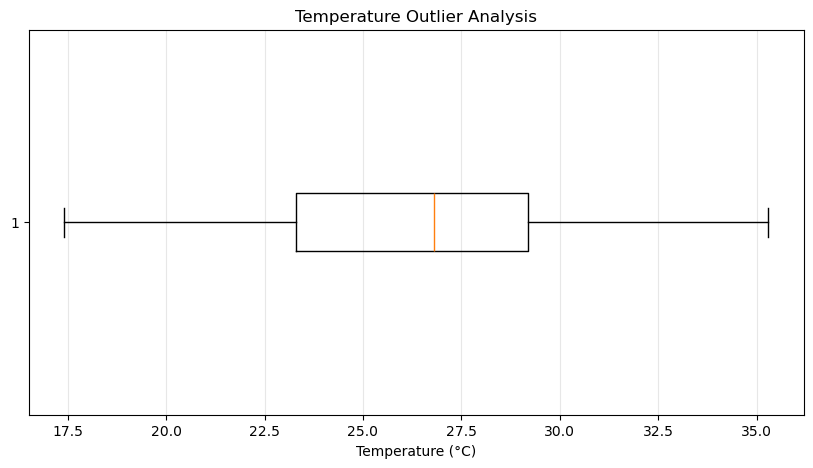

In [38]:
plt.figure(figsize=(10, 5))

plt.boxplot(df['temperature_c'].dropna(), vert=False)

plt.title("Temperature Outlier Analysis")
plt.xlabel("Temperature (°C)")
plt.grid(axis='x', alpha=0.3)

plt.show()

In [39]:
#Calculating IQR:
temp = df['temperature_c'].dropna()

Q1 = temp.quantile(0.25)
Q3 = temp.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = temp[(temp < lower_bound) | (temp > upper_bound)]

print("TEMPERATURE OUTLIER ANALYSIS")
print("----------------------------")
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Total Outliers:", len(outliers))
print("Outlier Values:", outliers.tolist())

TEMPERATURE OUTLIER ANALYSIS
----------------------------
Q1: 23.3
Q3: 29.2
IQR: 5.899999999999999
Lower Bound: 14.450000000000003
Upper Bound: 38.05
Total Outliers: 0
Outlier Values: []


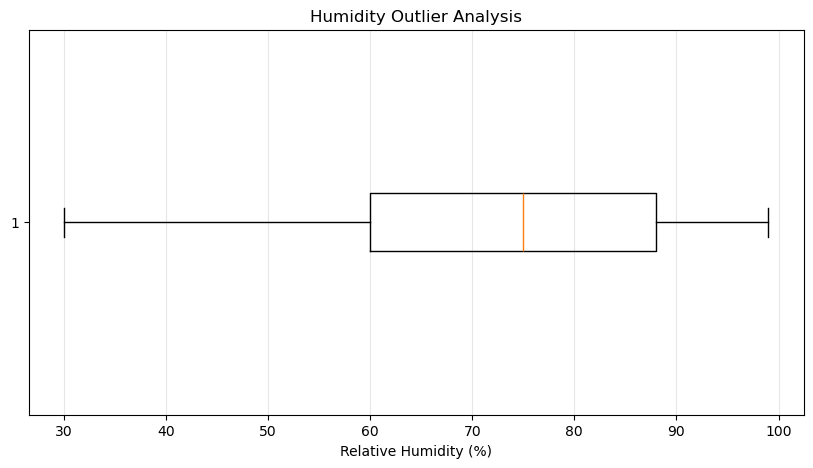

In [40]:
#Humidity Boxplot:
humidity = df['relative_humidity_pct'].dropna()

plt.figure(figsize=(10, 5))
plt.boxplot(humidity, vert=False)

plt.title("Humidity Outlier Analysis")
plt.xlabel("Relative Humidity (%)")
plt.grid(axis='x', alpha=0.3)

plt.show()

In [41]:
#Humidity Outliers:
Q1 = humidity.quantile(0.25)
Q3 = humidity.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = humidity[
    (humidity < lower_bound) | (humidity > upper_bound)
]

print("HUMIDITY OUTLIER ANALYSIS")
print("------------------------")
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Total Outliers:", len(outliers))
print("Outlier Values:", outliers.tolist())

HUMIDITY OUTLIER ANALYSIS
------------------------
Q1: 60.0
Q3: 88.0
IQR: 28.0
Lower Bound: 18.0
Upper Bound: 130.0
Total Outliers: 0
Outlier Values: []


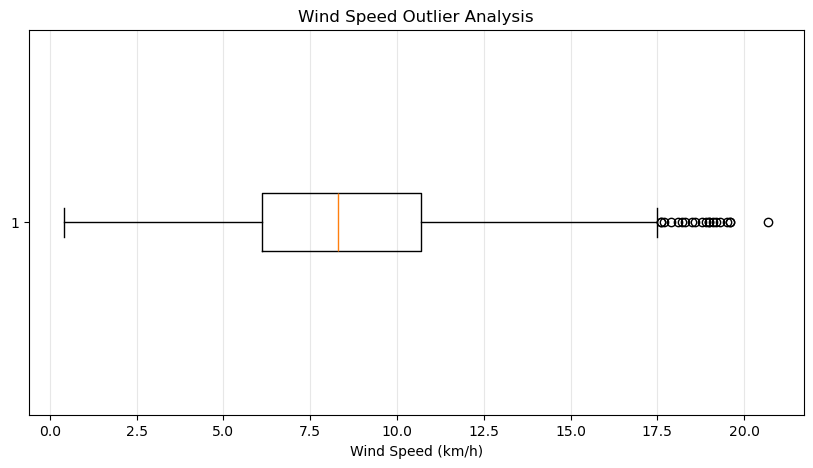

In [42]:
#Wind speed Boxplot:
wind = df['wind_speed_kmh'].dropna()

plt.figure(figsize=(10, 5))
plt.boxplot(wind, vert=False)

plt.title("Wind Speed Outlier Analysis")
plt.xlabel("Wind Speed (km/h)")
plt.grid(axis='x', alpha=0.3)

plt.show()

In [43]:
#Calculate Wind Speed Outliers:
Q1 = wind.quantile(0.25)
Q3 = wind.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = wind[
    (wind < lower_bound) | (wind > upper_bound)
]

print("WIND SPEED OUTLIER ANALYSIS")
print("--------------------------")
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Total Outliers:", len(outliers))
print("Outlier Values:", outliers.tolist())

WIND SPEED OUTLIER ANALYSIS
--------------------------
Q1: 6.1
Q3: 10.7
IQR: 4.6
Lower Bound: -0.7999999999999998
Upper Bound: 17.599999999999998
Total Outliers: 20
Outlier Values: [18.6, 19.1, 19.0, 18.5, 18.1, 17.7, 17.9, 18.3, 17.6, 17.6, 19.0, 19.6, 20.7, 18.8, 18.2, 19.3, 18.9, 19.6, 19.5, 19.2]


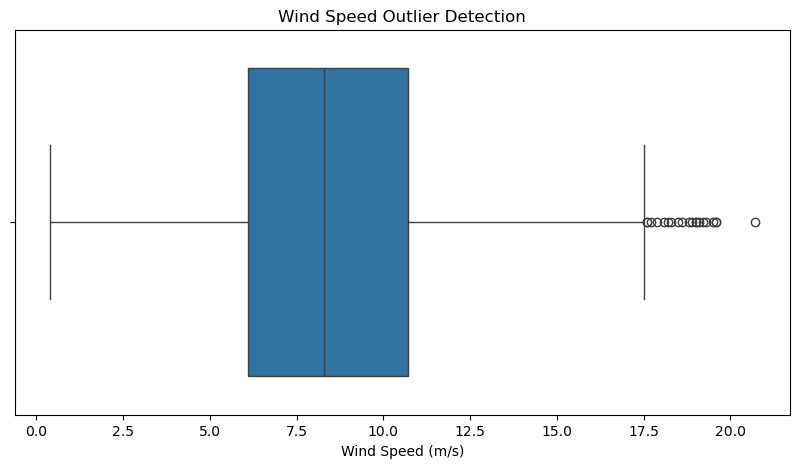

In [44]:

# WIND SPEED OUTLIER VISUALIZATION

plt.figure(figsize=(10, 5))

sns.boxplot(x=df['wind_speed_kmh'])

plt.title('Wind Speed Outlier Detection')
plt.xlabel('Wind Speed (m/s)')
plt.show()


In [45]:

# CHECK ALL COLUMN NAMES

print(df.columns.tolist())


['timestamp', 'city', 'latitude', 'longitude', 'elevation_m', 'temperature_c', 'relative_humidity_pct', 'wind_speed_kmh', 'precipitation_mm']



### Wind Speed Outlier Analysis

The boxplot indicates the presence of unusually high wind-speed observations.

Using the IQR method, 20 potential outliers were identified above the upper bound of 17.6 km/h.

These observations may represent periods of strong wind activity and should be investigated rather than removed automatically.


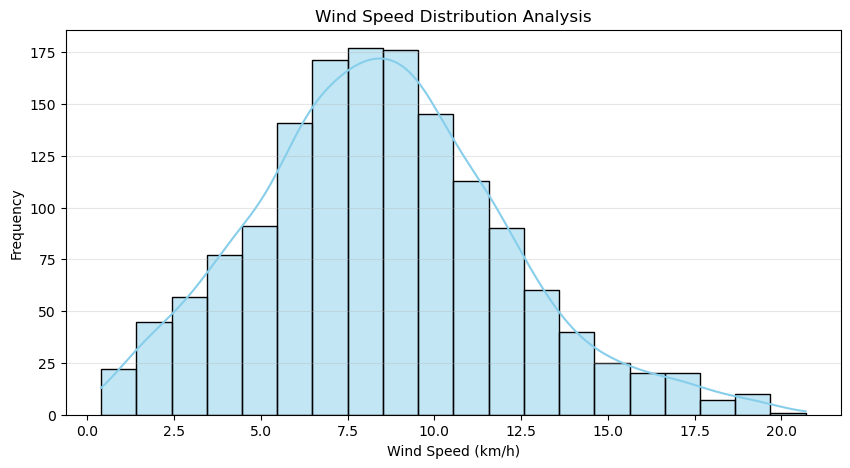

In [46]:

# WIND SPEED DISTRIBUTION ANALYSIS

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='wind_speed_kmh',
    bins=20,
    kde=True,
    color='skyblue'
)

plt.title('Wind Speed Distribution Analysis')
plt.xlabel('Wind Speed (km/h)')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.3)

plt.show()


In [47]:

# WIND SPEED STATISTICAL ANALYSIS

wind = df['wind_speed_kmh'].dropna()

print("WIND SPEED STATISTICAL ANALYSIS")
print("------------------------------")

print("Total Records:", len(wind))
print("Mean Wind Speed:", wind.mean())
print("Median Wind Speed:", wind.median())
print("Standard Deviation:", wind.std())
print("Minimum Wind Speed:", wind.min())
print("Maximum Wind Speed:", wind.max())
print("25th Percentile:", wind.quantile(0.25))
print("75th Percentile:", wind.quantile(0.75))


WIND SPEED STATISTICAL ANALYSIS
------------------------------
Total Records: 1488
Mean Wind Speed: 8.478763440860215
Median Wind Speed: 8.3
Standard Deviation: 3.6090941813944957
Minimum Wind Speed: 0.4
Maximum Wind Speed: 20.7
25th Percentile: 6.1
75th Percentile: 10.7



### Wind Speed Statistical Analysis – Observation

- A total of 1,488 wind speed records were analyzed.
- The average wind speed is approximately 8.48 km/h.
- The median wind speed is 8.3 km/h.
- The standard deviation of 3.61 indicates moderate variation in wind speed.
- Wind speed ranges from 0.4 km/h to 20.7 km/h.
- The mean is slightly higher than the median, indicating a slight right-skew in the distribution.

Overall, wind speed shows moderate variability with some unusually high observations.


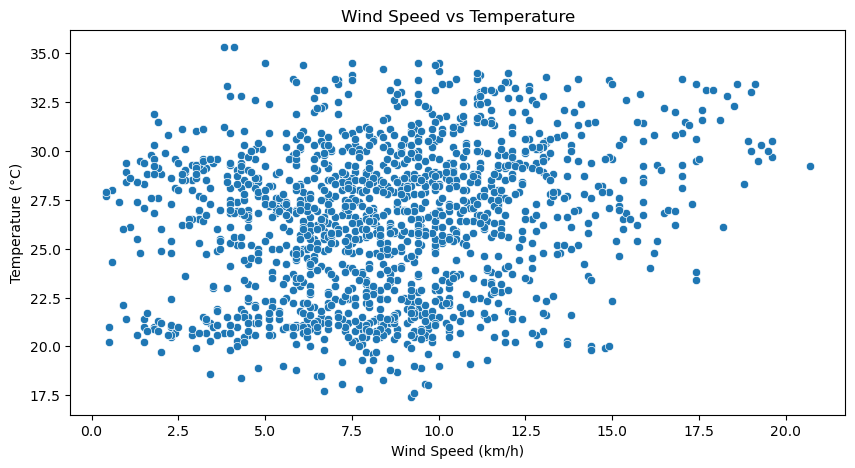

In [48]:

# WIND SPEED VS TEMPERATURE ANALYSIS

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x='wind_speed_kmh',
    y='temperature_c'
)

plt.title('Wind Speed vs Temperature')
plt.xlabel('Wind Speed (km/h)')
plt.ylabel('Temperature (°C)')
plt.show()


Completed wind speed exploratory data analysis (EDA), including IQR-based outlier detection, boxplot visualization, histogram distribution analysis, and statistical summary.

Analyzed 1,488 wind speed records and identified 20 potential outliers. Also created a scatter plot to explore the relationship between wind speed and temperature.

In [49]:
#Analysis using rainy observations only:
rainy_data = df.loc[
    df['precipitation_mm'] > 0,
    'precipitation_mm'
].dropna()

In [50]:
precip = df['precipitation_mm'].dropna()

### Precipitation Outlier Analysis – Interpretation

Two IQR-based approaches were used to analyse precipitation outliers.

1. **Complete Dataset:** Including zero-rainfall observations resulted in 234 potential outliers, with an upper IQR bound of 0.25 mm.

2. **Rainy Observations Only:** Excluding zero-rainfall observations resulted in 42 potential outliers, with an upper IQR bound of 2.1 mm.

The difference occurs because zero and low-precipitation observations reduce the overall interquartile range in the complete dataset.

The rainy-observation approach provides a more focused analysis of rainfall intensity, while the complete dataset approach examines precipitation relative to all observations.

These potential outliers should not automatically be considered errors, as they may represent genuine rainfall events.

Text(0.5, 0, 'Wind Speed (m/s)')

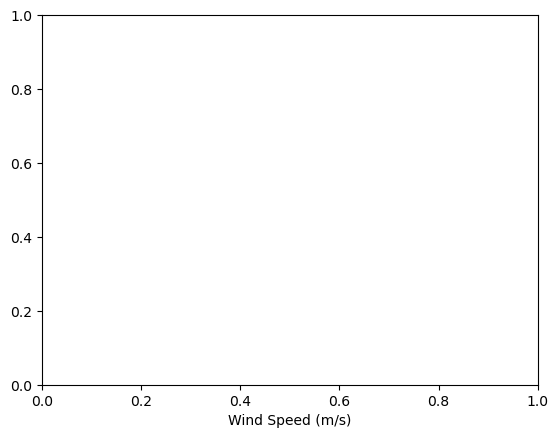

In [51]:
plt.xlabel('Wind Speed (m/s)')

Text(0.5, 0, 'Wind Speed (km/h)')

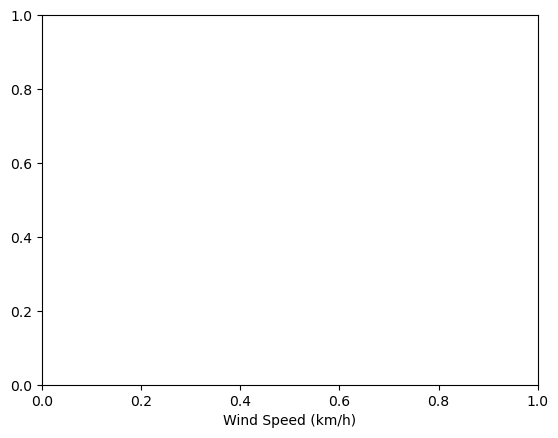

In [52]:
plt.xlabel('Wind Speed (km/h)')

In [53]:
#Calculatong the correlation:
# WIND SPEED VS TEMPERATURE CORRELATION

correlation = df['wind_speed_kmh'].corr(
    df['temperature_c']
)

print("Correlation between Wind Speed and Temperature:", correlation)

Correlation between Wind Speed and Temperature: 0.21355716653613158



### Observation – Wind Speed vs Temperature

- The correlation coefficient between wind speed and temperature is approximately 0.214.
- This indicates a weak positive correlation between the two variables.
- Wind speed tends to increase slightly with temperature, but the relationship is not strong.
- Other environmental factors may also influence wind speed.

**Conclusion:** Wind speed and temperature show a weak positive linear relationship in this dataset.


In [54]:
# WIND SPEED VS HUMIDITY CORRELATION

correlation = df['wind_speed_kmh'].corr(
    df['relative_humidity_pct']
)

print("Correlation between Wind Speed and Humidity:", correlation)

Correlation between Wind Speed and Humidity: -0.3016608400806466



### Observation – Wind Speed vs Relative Humidity

- The correlation coefficient between wind speed and relative humidity is approximately -0.302.
- This indicates a weak negative correlation between the two variables.
- As relative humidity increases, wind speed tends to decrease slightly.
- The relationship is not strong, suggesting that other environmental factors may influence wind speed.

**Conclusion:** Wind speed and relative humidity show a weak negative linear relationship in this dataset.


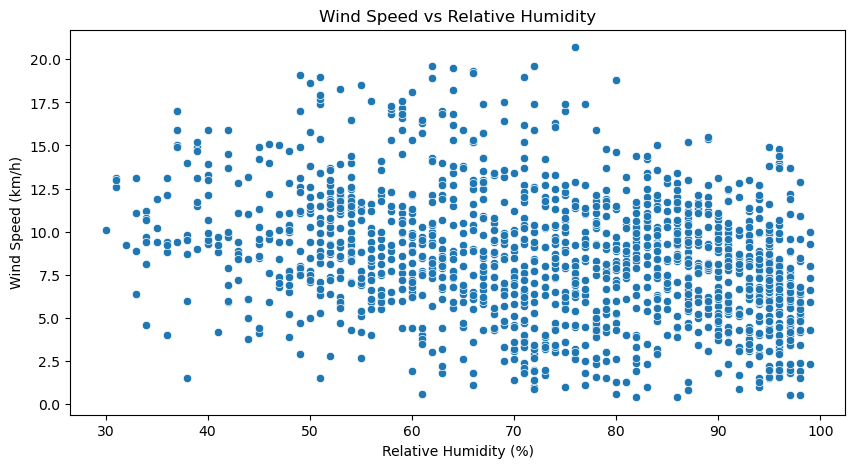

In [55]:
# WIND SPEED VS HUMIDITY SCATTER PLOT

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x='relative_humidity_pct',
    y='wind_speed_kmh'
)

plt.title('Wind Speed vs Relative Humidity')
plt.xlabel('Relative Humidity (%)')
plt.ylabel('Wind Speed (km/h)')
plt.show()

In [56]:
# WIND SPEED VS HUMIDITY CORRELATION

correlation = df['relative_humidity_pct'].corr(df['wind_speed_kmh'])

print("WIND SPEED VS HUMIDITY CORRELATION")
print("----------------------------------")
print("Correlation Coefficient:", correlation)

WIND SPEED VS HUMIDITY CORRELATION
----------------------------------
Correlation Coefficient: -0.3016608400806466


### Wind Speed vs Relative Humidity – Correlation

The correlation coefficient between relative humidity and wind speed is -0.3017.

This indicates a weak negative correlation, suggesting that wind speed tends to decrease slightly as relative humidity increases.

However, the relationship is relatively weak, indicating that relative humidity alone does not strongly explain variations in wind speed.

In [57]:
# TEMPERATURE VS PRECIPITATION CORRELATION

correlation = df['temperature_c'].corr(df['precipitation_mm'])

print("TEMPERATURE VS PRECIPITATION CORRELATION")
print("----------------------------------------")
print("Correlation Coefficient:", correlation)

TEMPERATURE VS PRECIPITATION CORRELATION
----------------------------------------
Correlation Coefficient: -0.07205040812084153


### Temperature vs Precipitation – Correlation

The correlation coefficient between temperature and precipitation is -0.0721.

This indicates a very weak negative correlation, suggesting that there is almost no linear relationship between temperature and precipitation in the dataset.

Therefore, temperature alone does not explain the variations in precipitation.

In [58]:
# HUMIDITY VS PRECIPITATION CORRELATION

correlation = df['relative_humidity_pct'].corr(df['precipitation_mm'])

print("HUMIDITY VS PRECIPITATION CORRELATION")
print("-------------------------------------")
print("Correlation Coefficient:", correlation)

HUMIDITY VS PRECIPITATION CORRELATION
-------------------------------------
Correlation Coefficient: 0.25280005596737243


### Humidity vs Precipitation – Correlation

The correlation coefficient between relative humidity and precipitation is 0.2528.

This indicates a weak positive correlation, suggesting that precipitation tends to increase slightly as relative humidity increases.

However, the relationship is relatively weak, indicating that other meteorological factors may also influence precipitation.

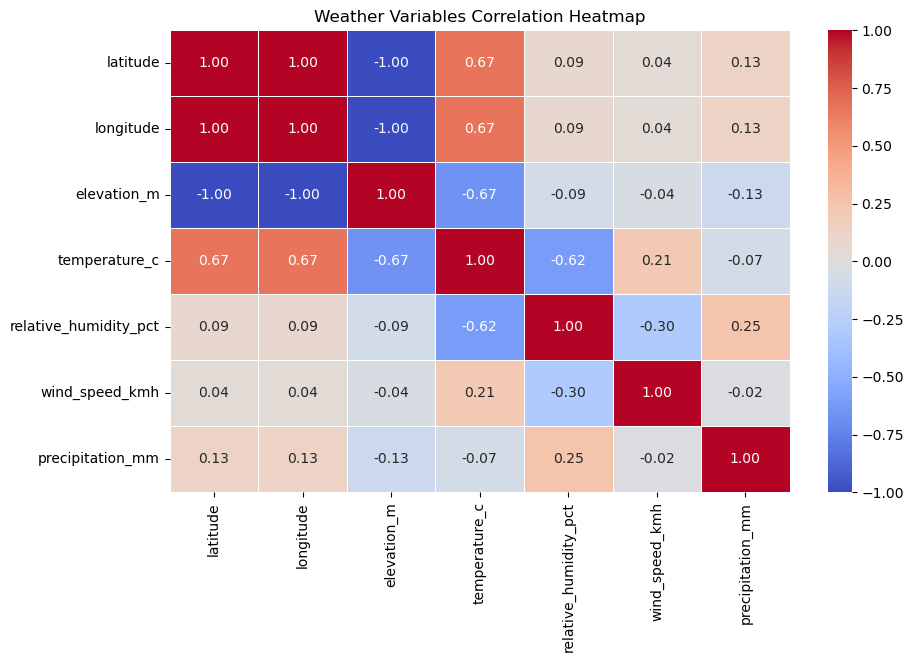

In [59]:
# CORRELATION HEATMAP

plt.figure(figsize=(10, 6))

correlation_matrix = df.select_dtypes(include='number').corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Weather Variables Correlation Heatmap')
plt.show()

In [60]:
# EXTRACT DATE FROM TIMESTAMP

df['date'] = df['timestamp'].dt.date

print("Date column created successfully!")
print(df[['timestamp', 'date', 'city']].head())


Date column created successfully!
            timestamp        date       city
0 2026-10-01 00:00:00  2026-10-01  Bengaluru
1 2026-10-01 00:00:00  2026-10-01    Chennai
2 2026-10-01 01:00:00  2026-10-01  Bengaluru
3 2026-10-01 01:00:00  2026-10-01    Chennai
4 2026-10-01 02:00:00  2026-10-01  Bengaluru


In [61]:
# DAILY AVERAGE TEMPERATURE BY CITY

daily_temp = df.groupby(
    ['date', 'city']
)['temperature_c'].mean().reset_index()

print(daily_temp.head(10))


         date       city  temperature_c
0  2026-10-01  Bengaluru      24.462500
1  2026-10-01    Chennai      30.025000
2  2026-10-02  Bengaluru      24.341667
3  2026-10-02    Chennai      30.345833
4  2026-10-03  Bengaluru      24.308333
5  2026-10-03    Chennai      30.291667
6  2026-10-04  Bengaluru      25.420833
7  2026-10-04    Chennai      30.875000
8  2026-10-05  Bengaluru      23.970833
9  2026-10-05    Chennai      30.891667


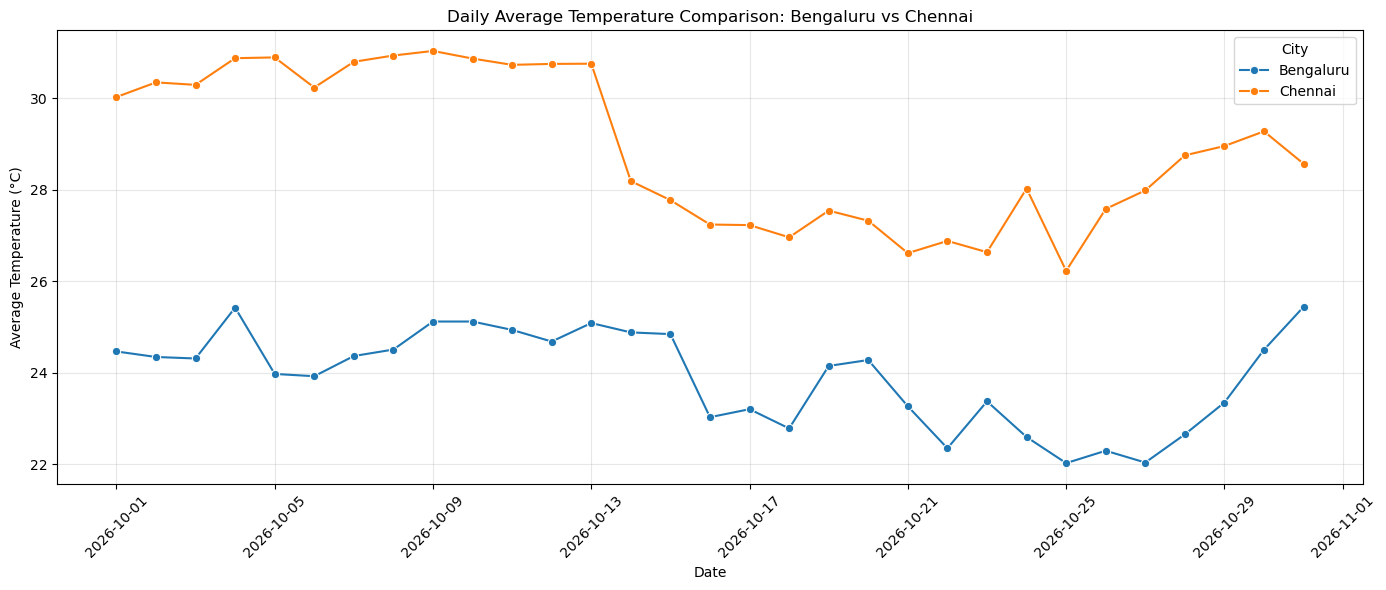

In [62]:
#Daily Average Temperature Line Plot:

# DAILY AVERAGE TEMPERATURE - TIME SERIES ANALYSIS

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=daily_temp,
    x='date',
    y='temperature_c',
    hue='city',
    marker='o'
)

plt.title('Daily Average Temperature Comparison: Bengaluru vs Chennai')
plt.xlabel('Date')
plt.ylabel('Average Temperature (°C)')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.legend(title='City')
plt.tight_layout()

plt.show()


In [63]:

# DAILY TEMPERATURE DIFFERENCE

temp_comparison = daily_temp.pivot(
    index='date',
    columns='city',
    values='temperature_c'
)

temp_comparison['temperature_difference'] = (
    temp_comparison['Chennai'] - temp_comparison['Bengaluru']
)

print(temp_comparison.head(10))


city        Bengaluru    Chennai  temperature_difference
date                                                    
2026-10-01  24.462500  30.025000                5.562500
2026-10-02  24.341667  30.345833                6.004167
2026-10-03  24.308333  30.291667                5.983333
2026-10-04  25.420833  30.875000                5.454167
2026-10-05  23.970833  30.891667                6.920833
2026-10-06  23.920833  30.233333                6.312500
2026-10-07  24.362500  30.795833                6.433333
2026-10-08  24.504167  30.933333                6.429167
2026-10-09  25.116667  31.033333                5.916667
2026-10-10  25.116667  30.866667                5.750000
